# Modelo de regresión - Viajes en taxi de Nueva York (enero 2015)

Se entrenó un modelo de regresión lineal multivariable sobre el dataset limpio `yellow_tripdata_2015-01_clean.csv` para predecir la duración del viaje (`trip_duration_min`) a partir de la distancia recorrida, la hora de partida y las coordenadas de partida y llegada.

### Importar datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PATH = "../data/yellow_tripdata_2015-01_clean.csv"
cols = {1: "tpep_pickup_datetime", 4: "trip_distance", 5: "pickup_longitude", 6: "pickup_latitude",
        9: "dropoff_longitude", 10: "dropoff_latitude", 19: "trip_duration_min"}

df = pd.read_csv(PATH, header=None, skiprows=1, usecols=list(cols))
df.columns = list(cols.values())
pickup = pd.to_datetime(df.pop("tpep_pickup_datetime"), format="%Y-%m-%d %H:%M:%S")
df.insert(1, "pickup_hour", pickup.dt.hour + pickup.dt.minute / 60)

features = ["trip_distance", "pickup_hour", "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude"]
X = df[features].to_numpy()
y = df["trip_duration_min"].to_numpy()

print(f"Filas: {len(df):,}")
print(f"Variables: {features}")

Filas: 12,402,772
Variables: ['trip_distance', 'pickup_hour', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude']


### Partición de datos

Se reserva el 20% de los datos como conjunto de test. El 80% restante se divide en K = 5 folds para validación cruzada (entrenamiento y validación).

In [2]:
K = 5
rng = np.random.default_rng(67)
idx = rng.permutation(len(df))

n_test = int(0.2 * len(df))
test_idx, train_idx = idx[:n_test], idx[n_test:]
folds = np.array_split(train_idx, K)

print(f"Train + validación: {len(train_idx):,}")
print(f"Test: {len(test_idx):,}")
print(f"Tamaño por fold: {len(folds[0]):,}")

Train + validación: 9,922,218
Test: 2,480,554
Tamaño por fold: 1,984,444


### Modelo

Regresión lineal multivariable `y = b0 + b1 x1 + ... + b6 x6` ajustada por mínimos cuadrados. Las variables se estandarizan con la media y desviación del conjunto de entrenamiento.

In [3]:
class LinearRegression:
    def fit(self, X, y):
        self.mean, self.std = X.mean(axis=0), X.std(axis=0)
        A = np.column_stack([np.ones(len(X)), (X - self.mean) / self.std])
        self.coef = np.linalg.lstsq(A, y, rcond=None)[0]
        return self

    def predict(self, X):
        return self.coef[0] + ((X - self.mean) / self.std) @ self.coef[1:]

def metricas(y, y_pred):
    err = y - y_pred
    mse = (err ** 2).mean()
    return {
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": np.abs(err).mean(),
        "R2": 1 - (err ** 2).sum() / ((y - y.mean()) ** 2).sum(),
    }

def resumen(res):
    out = pd.DataFrame(res).set_index("fold")
    out.loc["media"] = out.mean()
    out.loc["std"] = out.iloc[:K].std()
    return out

### Entrenamiento

Se entrena un modelo por fold con los K - 1 folds restantes.

In [4]:
models = []
train_res = []
for k in range(K):
    train_k = np.concatenate([folds[j] for j in range(K) if j != k])
    model = LinearRegression().fit(X[train_k], y[train_k])
    models.append(model)
    train_res.append({"fold": k + 1, **metricas(y[train_k], model.predict(X[train_k]))})

train_cv = resumen(train_res)
train_cv.round(4)

,MSE,RMSE,MAE,R2
fold,,,,
1,33.4806,5.7862,3.7802,0.6144
2,33.4880,5.7869,3.7803,0.6144
3,33.2822,5.7691,3.7786,0.6154
4,33.4732,5.7856,3.7812,0.6146
5,33.5574,5.7929,3.7821,0.6141
media,33.4563,5.7841,3.7805,0.6146
std,0.1030,0.0089,0.0013,0.0005


### Validación

Cada modelo se evalúa sobre el fold que no se usó en su entrenamiento.

In [5]:
val_res = [{"fold": k + 1, **metricas(y[folds[k]], models[k].predict(X[folds[k]]))} for k in range(K)]

val_cv = resumen(val_res)
val_cv.round(4)

,MSE,RMSE,MAE,R2
fold,,,,
1,33.3593,5.7758,3.7818,0.6154
2,33.3297,5.7732,3.7800,0.6155
3,34.1528,5.8440,3.7883,0.6114
4,33.3888,5.7783,3.7778,0.6144
5,33.0519,5.7491,3.7744,0.6163
media,33.4565,5.7841,3.7805,0.6146
std,0.4119,0.0355,0.0052,0.0019


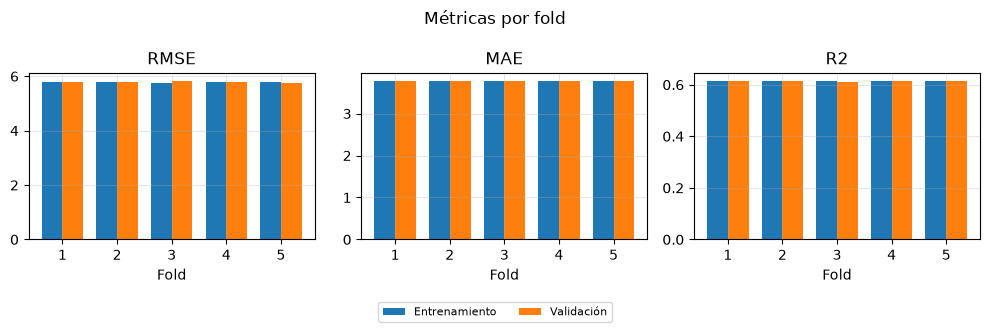

In [6]:
metric_names = ["RMSE", "MAE", "R2"]
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
w = 0.38
folds_x = np.arange(1, K + 1)
for ax, m in zip(axes, metric_names):
    ax.bar(folds_x - w / 2, train_cv[m].iloc[:K], w, label="Entrenamiento")
    ax.bar(folds_x + w / 2, val_cv[m].iloc[:K], w, label="Validación")
    ax.set_xticks(folds_x)
    ax.set_xlabel("Fold")
    ax.set_title(m)
    ax.grid(alpha=0.3)
handles, leg_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, leg_labels, loc="lower center", ncol=2, fontsize=8)
plt.suptitle("Métricas por fold")
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

### Modelo final

Se reentrena el modelo con todo el conjunto de entrenamiento y validación.

In [7]:
model = LinearRegression().fit(X[train_idx], y[train_idx])

print(f"Intercepto: {model.coef[0]:.4f}")
print("Coeficientes (variables estandarizadas):")
for f, c in zip(features, model.coef[1:]):
    print(f"  {f}: {c:.4f}")

Intercepto: 12.3570
Coeficientes (variables estandarizadas):
  trip_distance: 7.9744
  pickup_hour: 0.1940
  pickup_longitude: -0.8957
  pickup_latitude: 0.4223
  dropoff_longitude: -0.4474
  dropoff_latitude: -0.1872


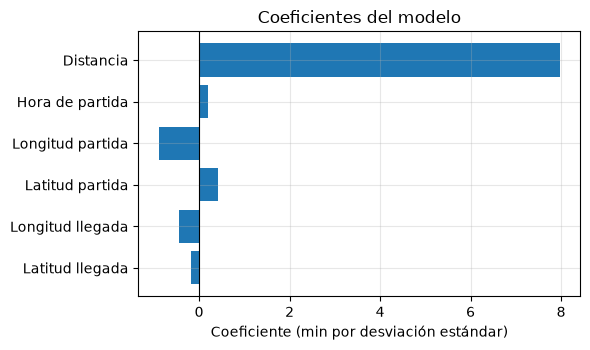

In [8]:
labels = {
    "trip_distance": "Distancia", "pickup_hour": "Hora de partida",
    "pickup_longitude": "Longitud partida", "pickup_latitude": "Latitud partida",
    "dropoff_longitude": "Longitud llegada", "dropoff_latitude": "Latitud llegada",
}

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.barh([labels[f] for f in features], model.coef[1:])
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("Coeficiente (min por desviación estándar)")
ax.grid(alpha=0.3)
plt.title("Coeficientes del modelo")
plt.tight_layout()
plt.show()

### Evaluación en test

El modelo final se evalúa sobre el conjunto de test. Las gráficas se realizaron sobre una muestra aleatoria de 500 mil viajes del conjunto de test, recortando los ejes al percentil 99 únicamente para mejorar la visualización.

In [9]:
y_pred = model.predict(X[test_idx])
test_metrics = metricas(y[test_idx], y_pred)

print("Métricas en test:")
for m, v in test_metrics.items():
    print(f"  {m}: {v:.4f}")

Métricas en test:
  MSE: 32.9040
  RMSE: 5.7362
  MAE: 3.7755
  R2: 0.6175


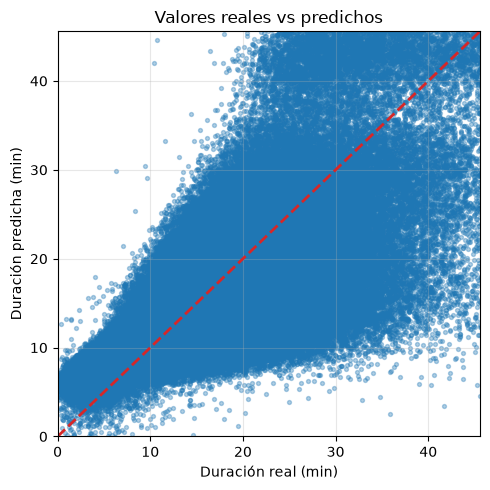

In [10]:
sample = rng.choice(len(test_idx), size=500_000, replace=False)
y_s, y_pred_s = y[test_idx][sample], y_pred[sample]
res_s = y_s - y_pred_s
y_max = np.quantile(y_s, 0.99)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_s, y_pred_s, s=8, alpha=0.35, rasterized=True)
ax.plot([0, y_max], [0, y_max], color="tab:red", lw=2, ls="--")
ax.set_xlim(0, y_max)
ax.set_ylim(0, y_max)
ax.set_xlabel("Duración real (min)")
ax.set_ylabel("Duración predicha (min)")
ax.grid(alpha=0.3)
plt.title("Valores reales vs predichos")
plt.tight_layout()
plt.show()

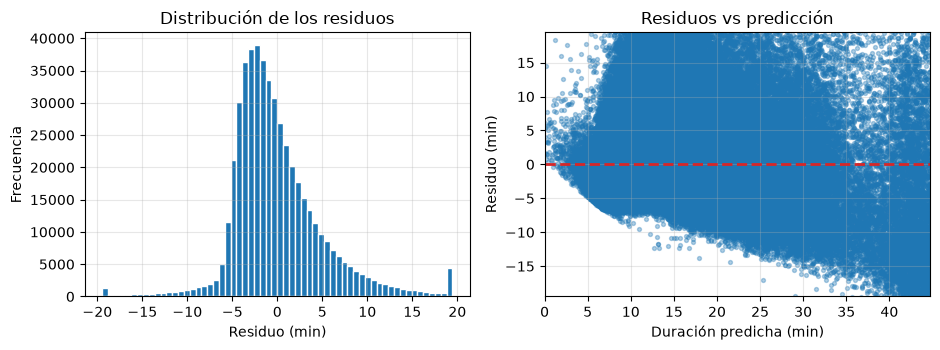

In [11]:
res_lim = np.quantile(np.abs(res_s), 0.99)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))

axes[0].hist(res_s.clip(-res_lim, res_lim), bins=60, edgecolor="white")
axes[0].set_xlabel("Residuo (min)")
axes[0].set_ylabel("Frecuencia")
axes[0].set_title("Distribución de los residuos")
axes[0].grid(alpha=0.3)

axes[1].scatter(y_pred_s, res_s, s=8, alpha=0.35, rasterized=True)
axes[1].axhline(0, color="tab:red", lw=2, ls="--")
axes[1].set_xlim(0, np.quantile(y_pred_s, 0.99))
axes[1].set_ylim(-res_lim, res_lim)
axes[1].set_xlabel("Duración predicha (min)")
axes[1].set_ylabel("Residuo (min)")
axes[1].set_title("Residuos vs predicción")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()